# Dataset exploration

## A. Static Cropped Images of Letters (Labeled)


In [8]:
import matplotlib.pyplot as plt
import numpy as np
from random import random
import pandas as pd
from keras.preprocessing.image import img_to_array, load_img


from handspell.utils import INDEX_TO_LETTER

def get_image_from_row_a01(row, plot=True):
    row = row.values[0]
    img_2828 = np.array(row[1:],
                        dtype=int).reshape(28,28, 1)
    letter = row[0]
    if plot:
        plt.imshow(img_2828, cmap="gray")
        plt.title(letter)
    return img_2828


def get_image_size_and_channels(image_path):
    img = load_img(image_path)
    width, height = img._size
    channels = img.layers
    return {"width": width,
            "height": height,
            "channels": channels
            }


In [2]:

def plot_example_images(dataset_df, get_image_from_row,
                        n_examples=5, figsize=(24, 10)):
    n_letters = len(INDEX_TO_LETTER.keys())

    # First half
    stop_i = int(n_letters/2)
    f, axs = plt.subplots(n_examples,stop_i,
                        figsize=figsize)

    for i, letter in INDEX_TO_LETTER.items():
        if i < n_letters/2:
            letter_bool = dataset_df["label"]==letter
            print(letter, letter_bool.sum())
            for j in range(n_examples):
                ax = axs[j, i]
                if letter_bool.sum() > 0:
                    random_row = dataset_df.loc[letter_bool].sample()
                    img = get_image_from_row(random_row)
                    ax.imshow(img, cmap="gray")
                ax.set_title(letter)
                ax.set_axis_off()

    f, axs = plt.subplots(n_examples,stop_i,
                        figsize=figsize)

    for i, letter in INDEX_TO_LETTER.items():
        if i >= n_letters/2:
            letter_bool = dataset_df["label"]==letter
            print(letter, letter_bool.sum())
            for j in range(n_examples):
                ax = axs[j, i-stop_i]
                if letter_bool.sum() > 0:
                    random_row = dataset_df.loc[letter_bool].sample()
                    img = get_image_from_row(random_row)
                    ax.imshow(img, cmap="gray")
                ax.set_title(letter)
                ax.set_axis_off()

In [ ]:
def save_a01_rows_as_images():
    train_df = pd.read_csv("../data/raw_data/A01_kaggle_aslmnist/sign_mnist_train.csv")
    for r in train_df.iterrows():

    test_df = pd.read_csv("../data/raw_data/A01_kaggle_aslmnist/sign_mnist_test.csv")

    img_2828 = get_image_from_row_a01(
        train_df.sample(),
        plot=False)


In [ ]:
# Get | dataset | train | label | width | height | channels |
def get_a01_dataset_infos(save=True):
    dataset_label = "A01_kaggle_aslmnist"
    dataset_path = "../data/raw_data/" + dataset_label

    train_df = pd.read_csv("../data/raw_data/A01_kaggle_aslmnist/sign_mnist_train.csv")
    test_df = pd.read_csv("../data/raw_data/A01_kaggle_aslmnist/sign_mnist_test.csv")
    train_df[["label"]]


In [ ]:
# Get | dataset | person | label | image_name | width | height | channels | image_path |
def get_b01_dataset_infos(save=True):
    dataset_label = "B01_original_aslmnist"
    dataset_path = "../data/raw_data/" + dataset_label
    rows = []
    exceptions = []
    for user_folder in os.listdir(dataset_path):
        try:
            folder_files = os.listdir(f"{dataset_path}/{user_folder}")
        except:
            exceptions += [f"{dataset_path}/{user_folder}"]
            continue
        for f in folder_files:
            try:
                img_props = get_image_size_and_channels(
                    dataset_path+"/"+user_folder+"/"+f
                )
                letter = f[0]
                rows += [dict(dataset=dataset_label,
                                person=user_folder,
                                label=letter,
                                image_name=f,
                                **img_props,
                                image_path=f"{dataset_path}/{user_folder}/{f}"
                        )]
            except:
                exceptions += [f"{dataset_path}/{user_folder}/{f}"]
    dataset_description_df = pd.DataFrame(rows)

    if save:
        dataset_description_df.to_csv(dataset_path+"/dataset_infos.csv", sep="\t")

    return dataset_description_df, dataset_path

### A01 - ASL MNIST (Kaggle: ([link](https://www.kaggle.com/datasets/datamunge/sign-language-mnist?select=sign_mnist_test))

- 28x28 grey-scaled images (1 channel) already flattened
- 24 classes of letters (excluding J and Z which require motion)
- 27,455 + 7,172 images (pre-split into train and test)
- result of applying a pre-processing pipeline to 1,704 color images (3 channels) - based on ImageMagick:
  - crop hands only
  - grey-scale
  - resize
  - data augmentation
    - filters ('Mitchell', 'Robidoux', 'Catrom', 'Spline', 'Hermite')
    - 5% random pixelation
    - +/- 15% brightness/contrast
    - 3 degrees rotation)

In [9]:
train_df = pd.read_csv("../data/raw_data/A01_kaggle_aslmnist/sign_mnist_train.csv")
test_df = pd.read_csv("../data/raw_data/A01_kaggle_aslmnist/sign_mnist_test.csv")

print(f"{train_df.shape[0]} train images")
print(f"{test_df.shape[0]} test images")

# Replace numbers with letters
train_df["label"] = train_df["label"].replace(INDEX_TO_LETTER)
test_df["label"] = test_df["label"].replace(INDEX_TO_LETTER)

train_df.head()

27455 train images
7172 test images


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,D,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,G,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,C,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,C,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,N,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [117]:
# Count number of images per letter
# No J, no Z
pd.DataFrame(train_df["label"].value_counts()).sort_index()

,count
label,
A,1126
B,1010
C,1144
D,1196
E,957
F,1204
G,1090
H,1013
I,1162


In [118]:
train_df.sample().values[0]

array(['V', 148, 153, 159, 163, 167, 169, 172, 174, 176, 178, 178, 191,
       173, 128, 170, 180, 179, 178, 177, 175, 175, 174, 173, 171, 171,
       170, 168, 167, 150, 155, 161, 164, 168, 171, 173, 176, 178, 179,
       179, 199, 181, 121, 147, 182, 179, 179, 179, 178, 177, 177, 174,
       174, 172, 172, 170, 169, 151, 157, 162, 166, 169, 173, 174, 178,
       180, 180, 181, 194, 192, 134, 128, 183, 181, 180, 181, 180, 179,
       179, 162, 152, 173, 173, 172, 171, 154, 159, 163, 167, 171, 173,
       177, 180, 181, 182, 183, 189, 205, 160, 126, 180, 183, 182, 182,
       181, 182, 182, 146, 107, 168, 175, 174, 173, 155, 160, 164, 169,
       172, 175, 178, 181, 183, 183, 185, 189, 218, 182, 127, 168, 187,
       185, 183, 182, 186, 178, 142, 104, 169, 177, 175, 175, 157, 162,
       166, 171, 174, 177, 180, 182, 185, 186, 187, 188, 219, 186, 129,
       152, 189, 186, 186, 184, 192, 171, 131, 115, 178, 178, 177, 176,
       158, 164, 168, 172, 175, 179, 182, 184, 186, 187, 188, 18

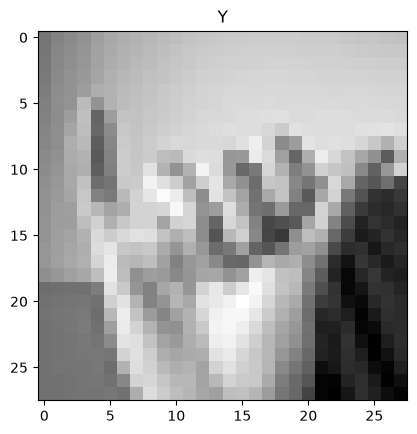

In [10]:
# Represent row as image

img_2828 = get_image_from_row_a01(
    train_df.sample(),
    plot=True)

A 1126
B 1010
C 1144
D 1196
E 957
F 1204
G 1090
H 1013
I 1162
J 0
K 1114
L 1241
M 1055
N 1151
O 1196
P 1088
Q 1279
R 1294
S 1199
T 1186
U 1161
V 1082
W 1225
X 1164
Y 1118
Z 0


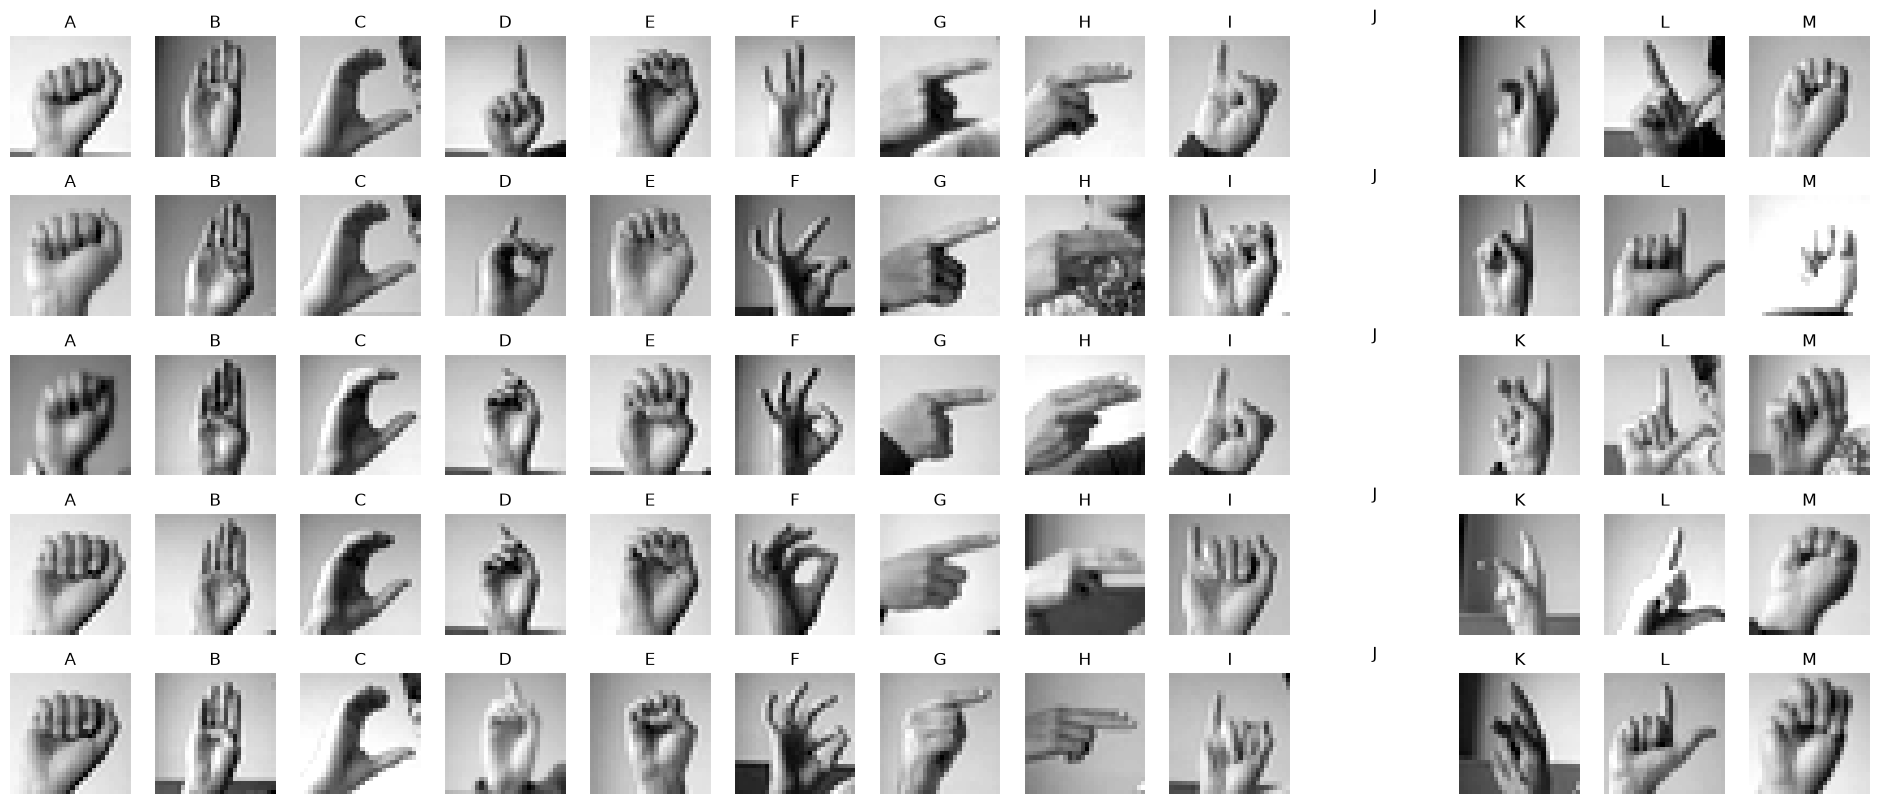

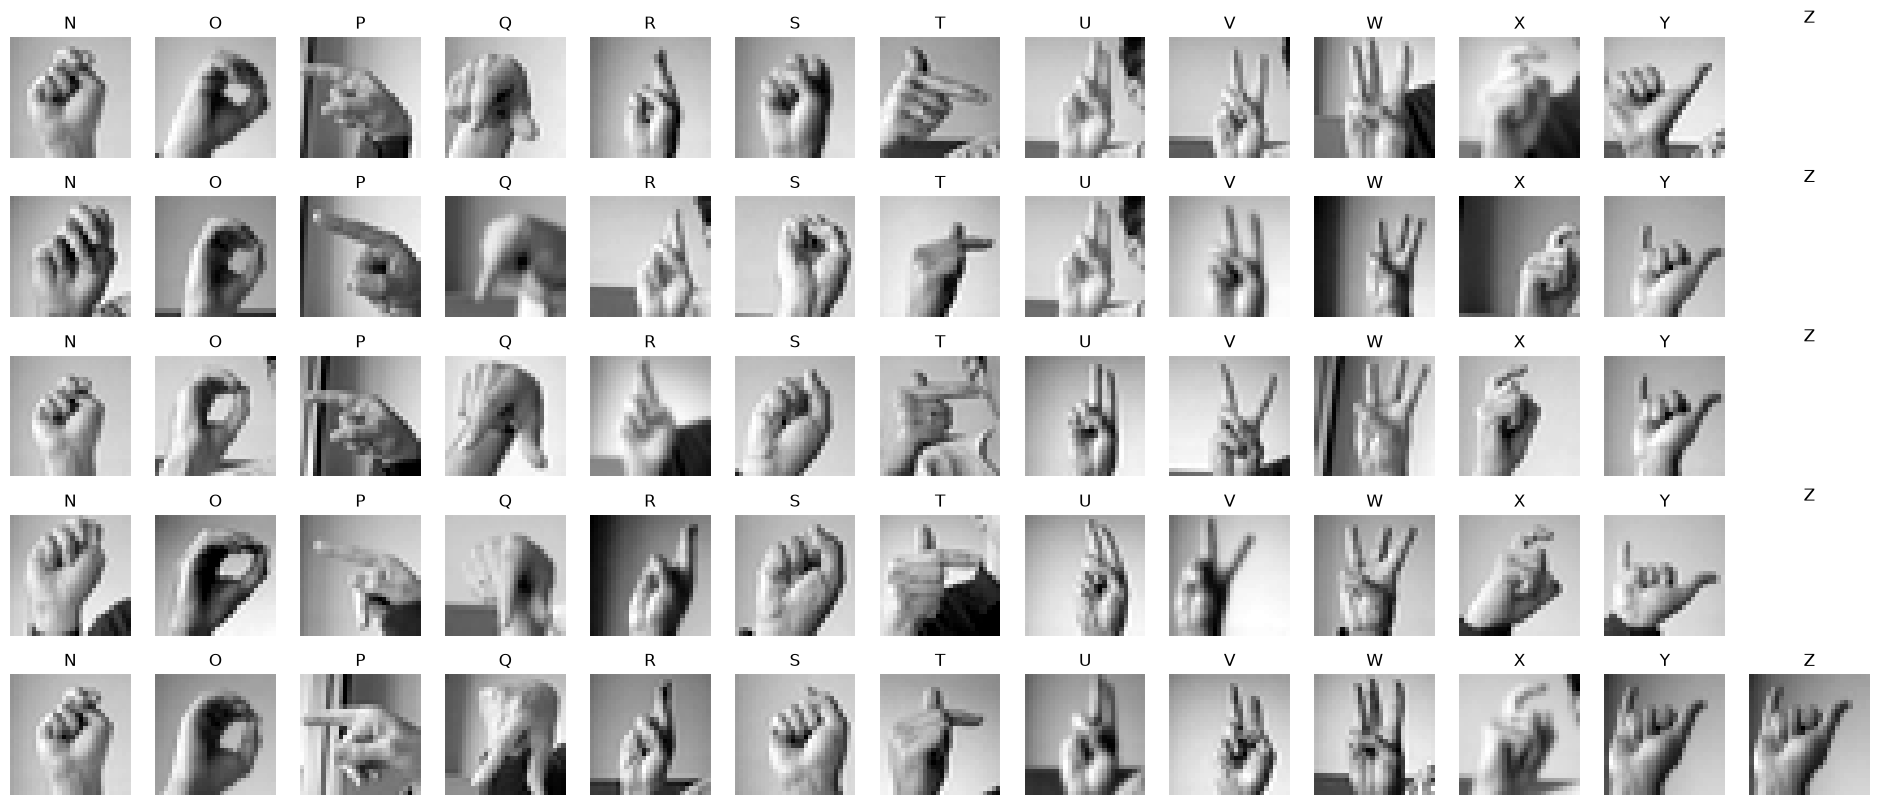

In [11]:
plot_example_images(train_df, get_image_from_row_a01,
                    n_examples=5, figsize=(24, 10))


In [12]:
# TODO: save all as images in the corresponding folder
# with first letter of the image name as the letter represented
# One folder per letter
from tensorflow.keras.utils import save_img
save_img("../data/preprocessed/test.jpg", img_2828)

## B. Non-cropped Static Images of Letters (Labeled)

In [138]:
infos_df, dataset_path = get_b01_dataset_infos()

dataset_description_df.head()

,dataset,person,label,image_name,width,height,channels,image_path
0,B01_original_aslmnist,user_5,C,C8.jpg,320,240,3,../data/raw_data/B01_original_aslmnist/user_5/...
1,B01_original_aslmnist,user_5,A,A0.jpg,320,240,3,../data/raw_data/B01_original_aslmnist/user_5/...
2,B01_original_aslmnist,user_5,L,L7.jpg,320,240,3,../data/raw_data/B01_original_aslmnist/user_5/...
3,B01_original_aslmnist,user_5,M,M3.jpg,320,240,3,../data/raw_data/B01_original_aslmnist/user_5/...
4,B01_original_aslmnist,user_5,X,X2.jpg,320,240,3,../data/raw_data/B01_original_aslmnist/user_5/...


In [139]:

n_images = infos_df.shape[0]
n_people = infos_df["person"].nunique()
min_width = infos_df["width"].min()
max_width = infos_df["width"].max()
min_height = infos_df["height"].min()
max_height = infos_df["height"].max()
min_channels = infos_df["channels"].min()
max_channels = infos_df["channels"].min()

print(f"Dataset: {infos_df["dataset"][0]}")
print(f"- {n_images} images")
print(f"- {n_people} different people")
if (min_width == max_width) and (min_height == max_height):
    print(f"- images {min_width}x{min_height} pixels")
else:
    print(f"- images ranging from {min_width} to {max_width} in pixel width")
    print(f"- images from {min_height} to {max_height} in pixel height")
if (min_channels == max_channels):
    if min_channels > 1:
        print(f"- All color images ({min_channels} channels)")
    else:
        print(f"- All greyscale images ({min_channel} channel)")
else:
    print(f"- Images ranging from {min_channels} to {max_channels} channels")

Dataset: B01_original_aslmnist
- 1680 images
- 7 different people
- images 320x240 pixels
- All color images (3 channels)


In [97]:
# Image sizes
dataset_description_df[["width", "height"]].describe()

,width,height
count,1680.0,1680.0
mean,320.0,240.0
std,0.0,0.0
min,320.0,240.0
25%,320.0,240.0
50%,320.0,240.0
75%,320.0,240.0
max,320.0,240.0


In [95]:
# Count number of images per letter
# No J, no Z
pd.DataFrame(dataset_description_df["label"].value_counts()).sort_index()

,count
label,
A,70
B,70
C,70
D,70
E,70
F,70
G,70
H,70
I,70


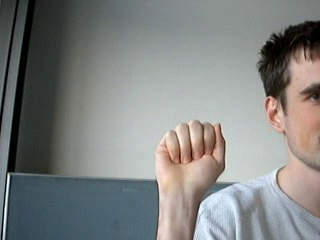

In [49]:
img = load_img(f"../data/raw_data/B01_original_aslmnist/user_6/A0.jpg")
img

In [101]:
get_image_size_and_channels(f"../data/raw_data/B01_original_aslmnist/user_6/A0.jpg")

{'width': 320, 'height': 240, 'channels': 3}

A 70
B 70
C 70
D 70
E 70
F 70
G 70
H 70
I 70
J 0
K 70
L 70
M 70
N 70
O 70
P 70
Q 70
R 70
S 70
T 70
U 70
V 70
W 70
X 70
Y 70
Z 0


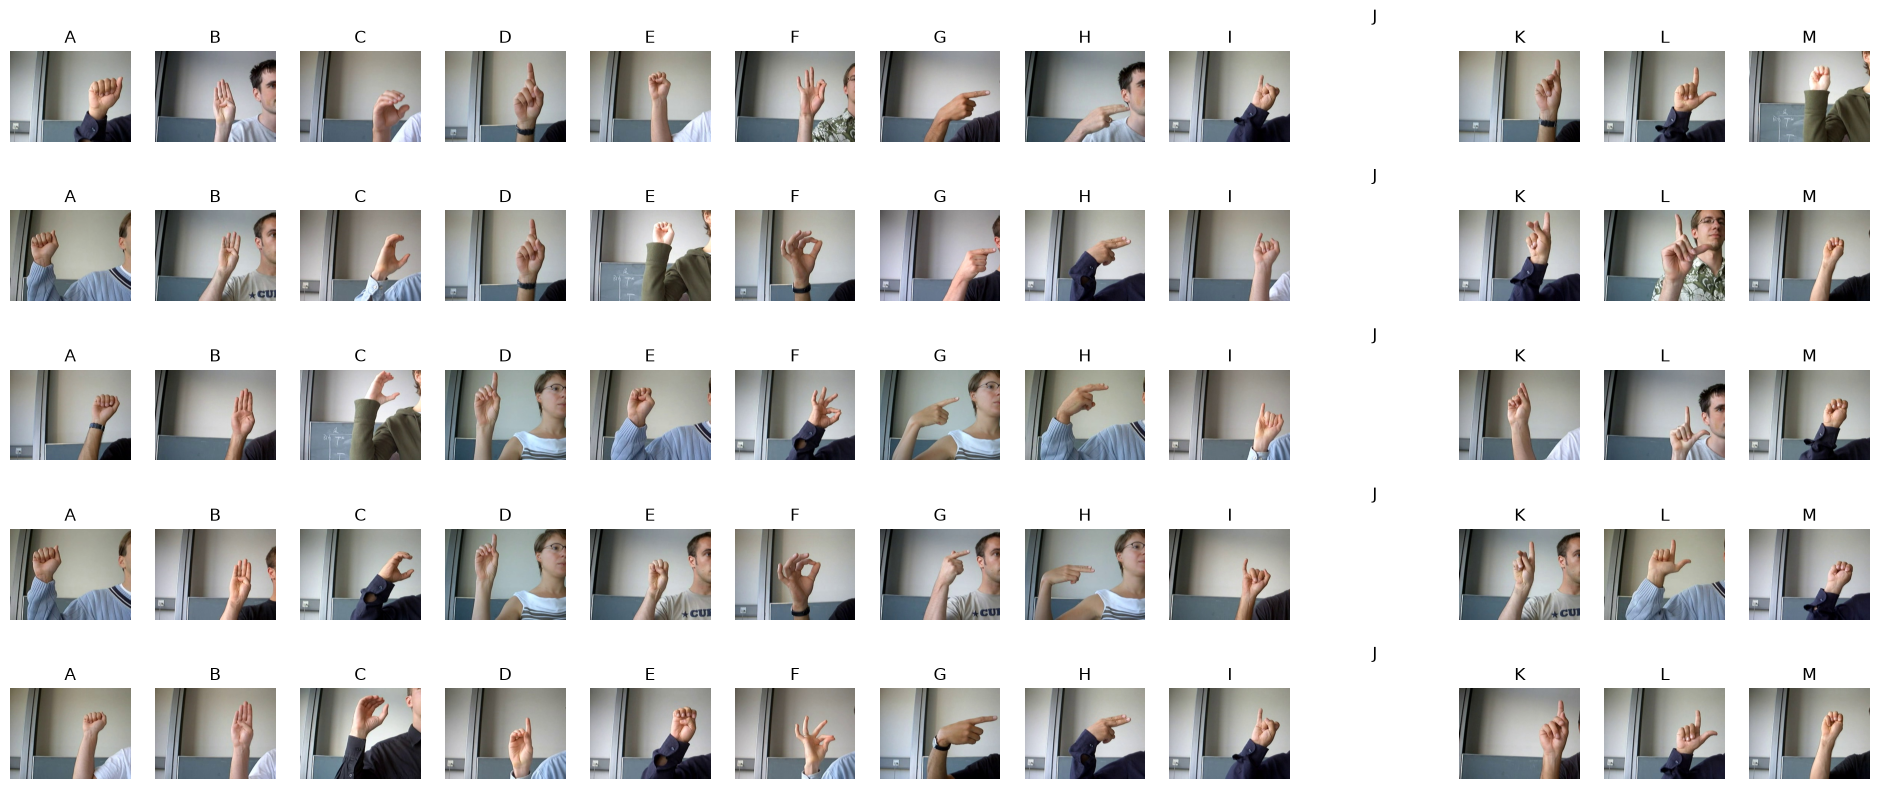

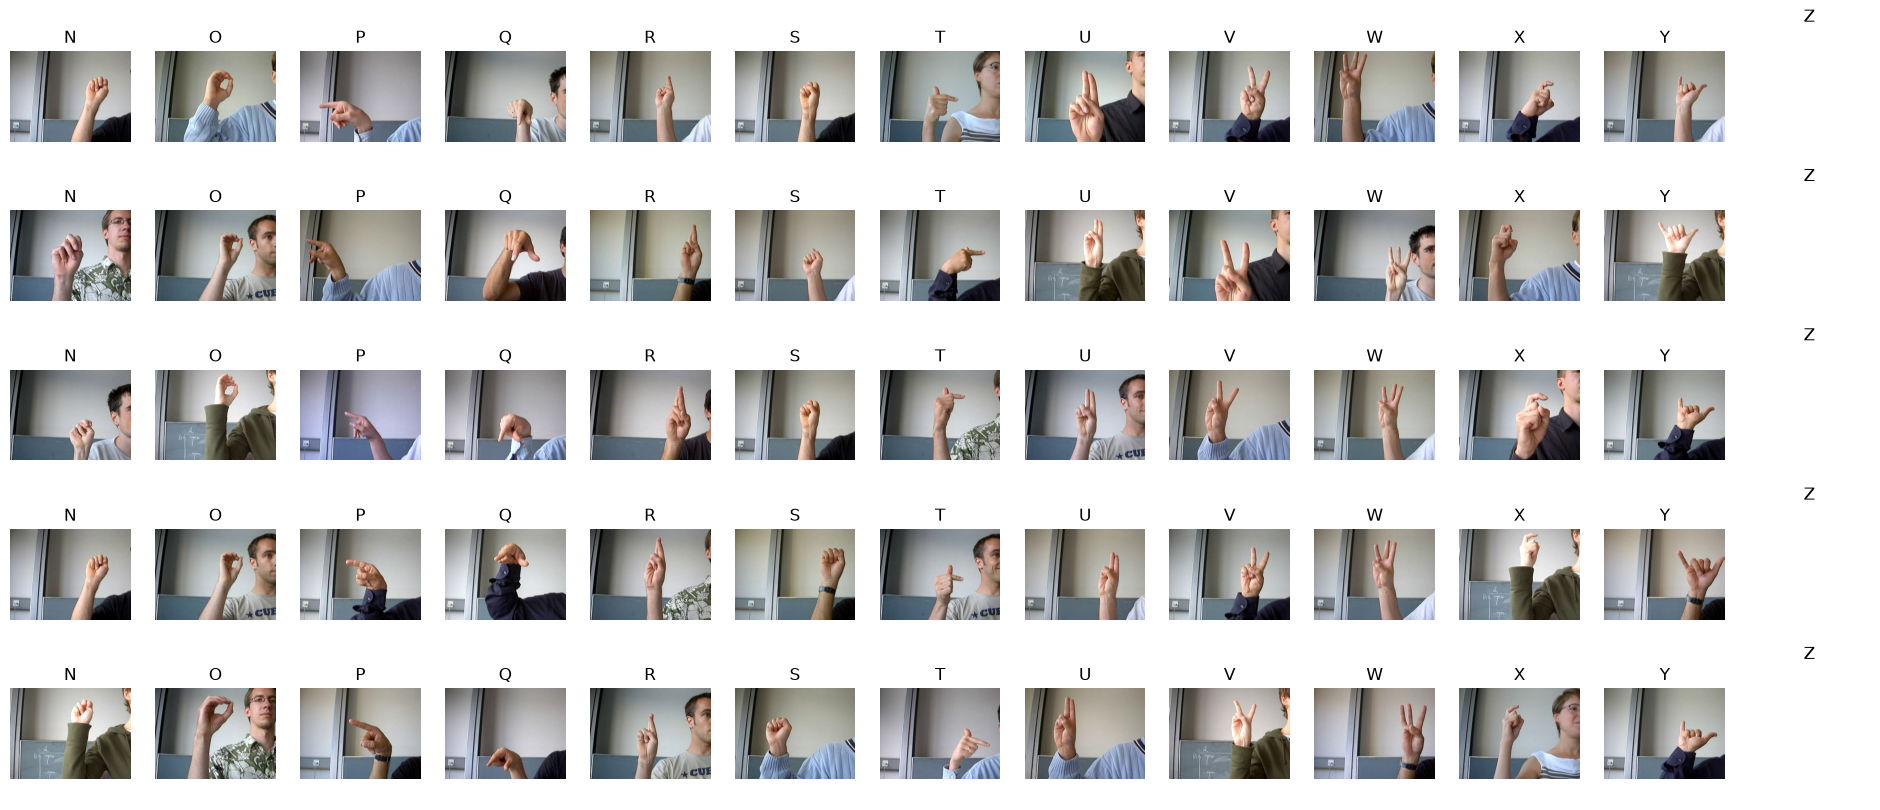

In [134]:
# chart with n random images per letter
def get_image_from_row_b01(row):
    img = load_img(row.iloc[0]["image_path"])
    return img

plot_example_images(infos_df, get_image_from_row_b01,
                    n_examples=5, figsize=(24, 10))
